In [ ]:
# Prodigy InfoTech - Generative AI Internship
# Task 04: Image-to-Image Translation using cGAN (Pix2Pix)

import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np

print("TensorFlow Version:", tf.__version__)
print("Task 04 Setup Completed!")

TensorFlow Version: 2.21.0
Task 04 Setup Completed!


In [ ]:
import pathlib

dataset_name = "facades"
_URL = f"http://efrosgans.eecs.berkeley.edu/pix2pix/datasets/{dataset_name}.tar.gz"

path_to_zip = tf.keras.utils.get_file(
    fname=f"{dataset_name}.tar.gz",
    origin=_URL,
    extract=True
)

PATH = pathlib.Path(path_to_zip).parent / "facades_extracted" / "facades"

print("Dataset downloaded successfully!")
print("Dataset path:", PATH)

30168306/30168306 ━━━━━━━━━━━━━━━━━━━━ 24s 1us/step
Dataset downloaded successfully!
Dataset path: /root/.keras/datasets/facades_extracted/facades


In [ ]:
import os

train_path = PATH / "train"
test_path = PATH / "val"

print("Training images:", len(os.listdir(train_path)))
print("Testing images:", len(os.listdir(test_path)))

Training images: 400
Testing images: 100


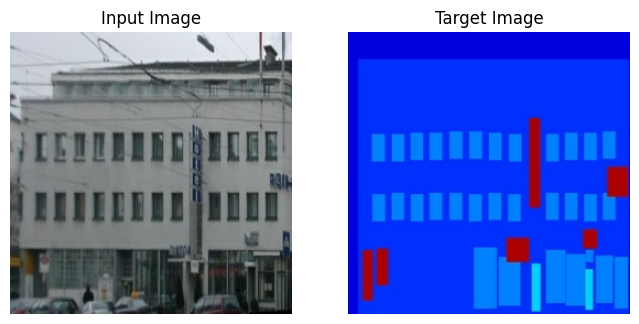

In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf

sample_path = next(train_path.glob("*.jpg"))

image = tf.io.read_file(str(sample_path))
image = tf.image.decode_jpeg(image)

input_image = image[:, :256, :]
target_image = image[:, 256:, :]

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(input_image)
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(target_image)
plt.title("Target Image")
plt.axis("off")

plt.show()

In [ ]:
IMG_SIZE = 256
BATCH_SIZE = 8

def load_image(image_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image)
    image = tf.cast(image, tf.float32)

    input_image = image[:, :256, :]
    target_image = image[:, 256:, :]

    input_image = tf.image.resize(input_image, [IMG_SIZE, IMG_SIZE])
    target_image = tf.image.resize(target_image, [IMG_SIZE, IMG_SIZE])

    input_image = (input_image / 127.5) - 1
    target_image = (target_image / 127.5) - 1

    return input_image, target_image

train_images = tf.data.Dataset.list_files(
    str(train_path / "*.jpg")
)

train_dataset = train_images.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE)

print("Image preprocessing completed!")

Image preprocessing completed!


In [ ]:
from tensorflow.keras import layers

def downsample(filters, size, apply_batchnorm=True):
    initializer = tf.random_normal_initializer(0., 0.02)

    result = tf.keras.Sequential()
    result.add(layers.Conv2D(
        filters, size, strides=2,
        padding="same",
        kernel_initializer=initializer,
        use_bias=False
    ))

    if apply_batchnorm:
        result.add(layers.BatchNormalization())

    result.add(layers.LeakyReLU())
    return result


def upsample(filters, size, apply_dropout=False):
    initializer = tf.random_normal_initializer(0., 0.02)

    result = tf.keras.Sequential()
    result.add(layers.Conv2DTranspose(
        filters, size, strides=2,
        padding="same",
        kernel_initializer=initializer,
        use_bias=False
    ))

    result.add(layers.BatchNormalization())

    if apply_dropout:
        result.add(layers.Dropout(0.5))

    result.add(layers.ReLU())
    return result


def Generator():
    inputs = layers.Input(shape=[256, 256, 3])

    down_stack = [
        downsample(64, 4, False),
        downsample(128, 4),
        downsample(256, 4),
        downsample(512, 4),
        downsample(512, 4),
        downsample(512, 4),
        downsample(512, 4),
        downsample(512, 4),
    ]

    up_stack = [
        upsample(512, 4, True),
        upsample(512, 4, True),
        upsample(512, 4, True),
        upsample(512, 4),
        upsample(256, 4),
        upsample(128, 4),
        upsample(64, 4),
    ]

    initializer = tf.random_normal_initializer(0., 0.02)

    last = layers.Conv2DTranspose(
        3, 4, strides=2,
        padding="same",
        kernel_initializer=initializer,
        activation="tanh"
    )

    x = inputs
    skips = []

    for down in down_stack:
        x = down(x)
        skips.append(x)

    skips = reversed(skips[:-1])

    for up, skip in zip(up_stack, skips):
        x = up(x)
        x = layers.Concatenate()([x, skip])

    x = last(x)

    return tf.keras.Model(inputs=inputs, outputs=x)


generator = Generator()
generator.summary()

print("Pix2Pix Generator created successfully!")

Model: "functional_15"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 128, 128,  │      3,072 │ input_layer[0][0] │
│ (Sequential)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_1        │ (None, 64, 64,    │    131,584 │ sequential[0][0]  │
│ (Sequential)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_2        │ (None, 32, 32,    │    525,312 │ sequential_1[0][… │
│ (Sequential)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_3        │ (None, 16, 16,    │  2,099,200 │ sequential_2[0][… │
│ (Sequential)        │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_4        │ (None, 8, 8, 512) │  4,196,352 │ sequential_3[0][… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_5        │ (None, 4, 4, 512) │  4,196,352 │ sequential_4[0][… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_6        │ (None, 2, 2, 512) │  4,196,352 │ sequential_5[0][… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_7        │ (None, 1, 1, 512) │  4,196,352 │ sequential_6[0][… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_8        │ (None, 2, 2, 512) │  4,196,352 │ sequential_7[0][… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 2, 2,      │          0 │ sequential_8[0][… │
│ (Concatenate)       │ 1024)             │            │ sequential_6[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_9        │ (None, 4, 4, 512) │  8,390,656 │ concatenate[0][0] │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 4, 4,      │          0 │ sequential_9[0][… │
│ (Concatenate)       │ 1024)             │            │ sequential_5[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_10       │ (None, 8, 8, 512) │  8,390,656 │ concatenate_1[0]… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 8, 8,      │          0 │ sequential_10[0]… │
│ (Concatenate)       │ 1024)             │            │ sequential_4[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_11       │ (None, 16, 16,    │  8,390,656 │ concatenate_2[0]… │
│ (Sequential)        │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 16, 16,    │          0 │ sequential_11[0]

 Total params: 54,425,859 (207.62 MB)

 Trainable params: 54,414,979 (207.58 MB)

 Non-trainable params: 10,880 (42.50 KB)

Pix2Pix Generator created successfully!


In [ ]:
def Discriminator():
    initializer = tf.random_normal_initializer(0., 0.02)

    input_image = layers.Input(shape=[256, 256, 3])
    target_image = layers.Input(shape=[256, 256, 3])

    x = layers.Concatenate()([input_image, target_image])

    down1 = downsample(64, 4, False)(x)
    down2 = downsample(128, 4)(down1)
    down3 = downsample(256, 4)(down2)

    zero_pad1 = layers.ZeroPadding2D()(down3)

    conv = layers.Conv2D(
        512, 4, strides=1,
        kernel_initializer=initializer,
        use_bias=False
    )(zero_pad1)

    batchnorm = layers.BatchNormalization()(conv)
    leaky_relu = layers.LeakyReLU()(batchnorm)

    zero_pad2 = layers.ZeroPadding2D()(leaky_relu)

    last = layers.Conv2D(
        1, 4, strides=1,
        kernel_initializer=initializer
    )(zero_pad2)

    return tf.keras.Model(
        inputs=[input_image, target_image],
        outputs=last
    )


discriminator = Discriminator()
discriminator.summary()

print("Pix2Pix Discriminator created successfully!")

Model: "functional_19"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_16      │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_17      │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_7       │ (None, 256, 256,  │          0 │ input_layer_16[0… │
│ (Concatenate)       │ 6)                │            │ input_layer_17[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_15       │ (None, 128, 128,  │      6,144 │ concatenate_7[0]… │
│ (Sequential)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_16       │ (None, 64, 64,    │    131,584 │ sequential_15[0]… │
│ (Sequential)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_17       │ (None, 32, 32,    │    525,312 │ sequential_16[0]… │
│ (Sequential)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 34, 34,    │          0 │ sequential_17[0]… │
│ (ZeroPadding2D)     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 31, 31,    │  2,097,152 │ zero_padding2d[0… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 31, 31,    │      2,048 │ conv2d_11[0][0]   │
│ (BatchNormalizatio… │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_11      │ (None, 31, 31,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_1    │ (None, 33, 33,    │          0 │ leaky_re_lu_11[0… │
│ (ZeroPadding2D)     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 30, 30, 1) │      8,193 │ zero_padding2d_1… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,770,433 (10.57 MB)

 Trainable params: 2,768,641 (10.56 MB)

 Non-trainable params: 1,792 (7.00 KB)

Pix2Pix Discriminator created successfully!


In [ ]:
loss_object = tf.keras.losses.BinaryCrossentropy(from_logits=True)

generator_optimizer = tf.keras.optimizers.Adam(
    2e-4, beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    2e-4, beta_1=0.5
)

def generator_loss(disc_generated_output, gen_output, target):
    gan_loss = loss_object(
        tf.ones_like(disc_generated_output),
        disc_generated_output
    )

    l1_loss = tf.reduce_mean(tf.abs(target - gen_output))

    total_gen_loss = gan_loss + (100 * l1_loss)

    return total_gen_loss


def discriminator_loss(disc_real_output, disc_generated_output):
    real_loss = loss_object(
        tf.ones_like(disc_real_output),
        disc_real_output
    )

    generated_loss = loss_object(
        tf.zeros_like(disc_generated_output),
        disc_generated_output
    )

    return real_loss + generated_loss


print("Loss functions and optimizers configured successfully!")

Loss functions and optimizers configured successfully!


In [ ]:
@tf.function
def train_step(input_image, target):
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:

        gen_output = generator(input_image, training=True)

        disc_real_output = discriminator(
            [input_image, target], training=True
        )

        disc_generated_output = discriminator(
            [input_image, gen_output], training=True
        )

        gen_loss = generator_loss(
            disc_generated_output, gen_output, target
        )

        disc_loss = discriminator_loss(
            disc_real_output, disc_generated_output
        )

    generator_gradients = gen_tape.gradient(
        gen_loss, generator.trainable_variables
    )

    discriminator_gradients = disc_tape.gradient(
        disc_loss, discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(generator_gradients, generator.trainable_variables)
    )

    discriminator_optimizer.apply_gradients(
        zip(discriminator_gradients, discriminator.trainable_variables)
    )

    return gen_loss, disc_loss


print("Training function created successfully!")

Training function created successfully!


In [ ]:
EPOCHS = 2

for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    for step, (input_image, target_image) in enumerate(train_dataset):
        gen_loss, disc_loss = train_step(
            input_image, target_image
        )

        if step % 50 == 0:
            print(
                f"Step {step} | "
                f"Generator Loss: {gen_loss:.4f} | "
                f"Discriminator Loss: {disc_loss:.4f}"
            )

print("\nTraining completed successfully!")


Epoch 1/2
Step 0 | Generator Loss: 77.6593 | Discriminator Loss: 1.7562

Epoch 2/2
Step 0 | Generator Loss: 45.2677 | Discriminator Loss: 0.5090

Training completed successfully!


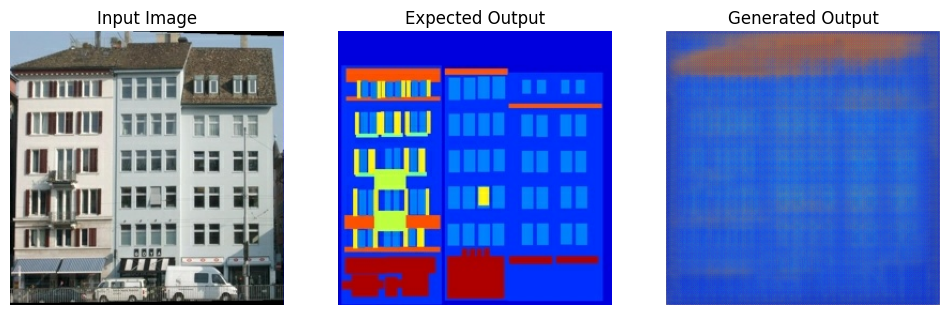

In [12]:
for input_image, target_image in train_dataset.take(1):
    prediction = generator(input_image, training=False)

plt.figure(figsize=(12, 4))

display_list = [
    input_image[0],
    target_image[0],
    prediction[0]
]

titles = ["Input Image", "Expected Output", "Generated Output"]

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.title(titles[i])
    plt.imshow((display_list[i] * 0.5) + 0.5)
    plt.axis("off")

plt.show()

In [13]:
generated_image = (prediction[0] + 1) * 127.5
generated_image = tf.clip_by_value(generated_image, 0, 255)
generated_image = tf.cast(generated_image, tf.uint8)

tf.keras.utils.save_img(
    "pix2pix_generated_output.png",
    generated_image
)

print("Generated image saved successfully!")

Generated image saved successfully!


In [14]:
from google.colab import files

files.download("pix2pix_generated_output.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>